# Artist Popularity Score v2 — Principal-Components Version

**Goal.** Replace the percentile average with scores that are not a relabelled stream count. Instead of one blended number, the artist is described by a few **uncorrelated dimensions** that can all enter the song-level quantile regressions.

**What changed relative to v1**

| | v1 | v2 (this notebook) |
|---|---|---|
| Transform | `log1p`, then percentile rank | `log1p` (or a share), then **z-score**: magnitude is kept |
| Combination | fixed 0.5 / 0.5 weights | principal components of standardised variables |
| Output | one number | **three orthogonal scores**: `size`, `momentum`, `solo_orientation` |

**Variables** (all from `artists.csv`; Streams in millions, Daily in millions/day)

| Variable | Definition | Transformation |
|---|---|---|
| `log_lifetime` | lifetime streams | `log1p` |
| `log_daily` | current daily streams | `log1p` |
| `feature_share` | `As feature / Streams` | share in [0, 1] |
| `solo_share` | `Solo / Streams` | share in [0, 1] |

**Method.** $z_{ij}=(x_{ij}-\bar x_j)/s_j$. A principal component is $\text{PC}_{ik}=\sum_j w_{kj}z_{ij}$ with orthonormal weights chosen to maximise variance. Scores are rescaled to unit variance, so a regression coefficient is *popularity points per 1 SD of that dimension*.

**Why block-wise PCA.** The four variables form two nearly uncorrelated blocks (stream variables vs. credit-share variables; see section 3). A PCA on all four at once has two eigenvalues that are almost equal, which means the first two components are an arbitrary mix of the blocks. Running PCA **within each block** gives components with a clear meaning:

| Score | Block | Reading (high value means) |
|---|---|---|
| `size` | streams, PC1 | large lifetime *and* large daily streams |
| `momentum` | streams, PC2 | daily streams high *relative to* career size |
| `solo_orientation` | credits, PC1 | most streams come from solo credits; low means feature-heavy |

**Limitations**
- Each block has two variables, so within-block PCA weights are fixed at ±0.707 by mathematics (`size` is the average of two z-scores and `momentum` their difference). What the data contribute is the *variance split* between dimensions, not free weights.
- `momentum` is orthogonal to `size`, but not to lifetime streams alone. Check the correlation table in section 5.
- Scores are relative to this sample of about 3,000 artists.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

# ---------------- configuration ----------------
RNG_SEED = 0
N_BOOT   = 500                     # bootstrap draws
OUT_FILE = Path("artist_pca_scores.csv")

# block PCA: which variables form each block and which components are kept
BLOCKS = {
    "streams":     ["log_lifetime", "log_daily"],
    "composition": ["feature_share", "solo_share"],
}
# (block, component index, variable that must load positively, output name)
SCORES = [
    ("streams",     0, "log_lifetime", "size"),
    ("streams",     1, "log_daily",    "momentum"),
    ("composition", 0, "solo_share",   "solo_orientation"),
]

## 1. Load `artists.csv`

Numbers contain thousands separators, so they are read as text and converted. **Blank role columns are structural zeros:** in this file every artist with a blank `As feature` has `As lead == Streams`, every artist with a blank `As lead` has `As feature == Streams`, and no explicit 0 ever appears in the role columns. A blank therefore means "no credits in that role", and the notebook fills it with 0. Dropping those artists instead would remove mostly solo-only acts and bias the sample.

In [2]:
def find_file(name):
    p = Path(name)
    if p.exists(): return p
    for parent in Path.cwd().parents:
        if (parent / name).exists(): return parent / name
    raise FileNotFoundError(f"{name} not found next to this notebook")

src = find_file("artists.csv")
raw = pd.read_csv(src)
NUM = ["Streams", "Daily", "As lead", "Solo", "As feature"]
for c in NUM:   # float64 explicitly: pandas' nullable Float64 makes .values an object array
    raw[c] = pd.to_numeric(raw[c].astype("string").str.replace(",", "", regex=False), errors="coerce").astype("float64")

print("Source:", src, "| shape:", raw.shape)
print("\nMissing values before cleaning:"); print(raw[NUM].isna().sum().to_string())

df = raw.loc[(raw["Streams"] > 0) & (raw["Daily"] >= 0)].copy().reset_index(drop=True)   # drops rows with no Daily value
n_blank = df[["As lead", "Solo", "As feature"]].isna().sum()
df[["As lead", "Solo", "As feature"]] = df[["As lead", "Solo", "As feature"]].fillna(0.0)   # blank = no credits in that role

# consistency check: lead + feature should equal total streams
gap = (df["As lead"] + df["As feature"] - df["Streams"]).abs() / df["Streams"]
print(f"\nArtists kept: {len(df):,} (dropped {len(raw)-len(df)} with no Daily value)")
print("Blank role values filled with 0:", n_blank.to_dict())
print(f"Share of artists where lead + feature equals Streams (within 0.1%): {(gap < 1e-3).mean():.3f}")

Source: artists.csv | shape: (3000, 6)

Missing values before cleaning:
Streams         0
Daily           6
As lead        16
Solo           69
As feature    338

Artists kept: 2,994 (dropped 6 with no Daily value)
Blank role values filled with 0: {'As lead': 16, 'Solo': 69, 'As feature': 335}
Share of artists where lead + feature equals Streams (within 0.1%): 1.000


## 2. Build and standardise the variables

In [3]:
feat = pd.DataFrame(index=df.index)
feat["log_lifetime"]  = np.log1p(df["Streams"])
feat["log_daily"]     = np.log1p(df["Daily"])
feat["feature_share"] = (df["As feature"] / df["Streams"]).clip(0, 1)
feat["solo_share"]    = (df["Solo"] / df["Streams"]).clip(0, 1)
feat = feat.astype("float64")

Z = (feat - feat.mean()) / feat.std(ddof=0)
print(f"n = {len(Z):,} artists")
display(feat.describe().T.round(3))
print("Correlation matrix of the inputs:")
display(feat.corr().round(3))

n = 2,994 artists


,count,mean,std,min,25%,50%,75%,max
log_lifetime,2994.0,7.508,0.818,6.592,6.871,7.288,7.895,11.351
log_daily,2994.0,0.798,0.581,0.002,0.392,0.626,1.020,4.464
feature_share,2994.0,0.243,0.267,0.000,0.018,0.147,0.385,1.000
solo_share,2994.0,0.538,0.348,0.000,0.217,0.551,0.890,1.000


Correlation matrix of the inputs:


,log_lifetime,log_daily,feature_share,solo_share
log_lifetime,1.000,0.822,0.050,-0.044
log_daily,0.822,1.000,0.040,-0.025
feature_share,0.050,0.040,1.000,-0.749
solo_share,-0.044,-0.025,-0.749,1.000


## 3. Diagnostic: PCA on all four variables at once

The correlation table above shows two blocks: stream variables correlate at about 0.8 with each other and at about 0 with the credit shares. In a joint PCA, the first two eigenvalues are therefore close, and their components are mixtures of the two blocks. This section is kept to document that choice; it does not feed the exported scores.

In [4]:
pca_all = PCA().fit(Z)
ev = pd.DataFrame({"eigenvalue": pca_all.explained_variance_,
                   "share": pca_all.explained_variance_ratio_}, index=[f"PC{i+1}" for i in range(Z.shape[1])])
ev["cumulative"] = ev["share"].cumsum()
print("Joint PCA (diagnostic):"); display(ev.round(3))
print("Joint loadings (note the mixing of stream and credit variables):")
display(pd.DataFrame(pca_all.components_.T, index=Z.columns, columns=ev.index).round(3))

Joint PCA (diagnostic):


,eigenvalue,share,cumulative
PC1,1.874,0.468,0.468
PC2,1.699,0.425,0.893
PC3,0.251,0.063,0.956
PC4,0.177,0.044,1.000


Joint loadings (note the mixing of stream and credit variables):


,PC1,PC2,PC3,PC4
log_lifetime,0.599,0.375,0.049,-0.706
log_daily,0.593,0.386,-0.039,0.706
feature_share,0.385,-0.593,-0.706,-0.038
solo_share,-0.377,0.599,-0.705,-0.050


## 4. Block-wise PCA: the scores

Signs of principal components are arbitrary, so each kept component is flipped so that the named variable loads positively. Loadings and within-block variance shares are printed so the labels can be checked against what the data say.

In [5]:
def block_components(cols):
    p = PCA().fit(Z[cols])
    return p.components_.copy(), p.explained_variance_ratio_

W_blocks, share_blocks = {}, {}
for b, cols in BLOCKS.items():
    W_blocks[b], share_blocks[b] = block_components(cols)

score_cols, load_rows = {}, []
for block, k, var, name in SCORES:
    cols = BLOCKS[block]
    w = W_blocks[block][k].copy()
    if w[cols.index(var)] < 0: w = -w
    s = Z[cols].to_numpy(dtype=float) @ w
    score_cols[name] = (s - s.mean()) / s.std()
    for c, wi in zip(cols, w):
        load_rows.append({"score": name, "block": block, "variable": c, "loading": wi,
                          "block-variance share": share_blocks[block][k]})
scores_z = pd.DataFrame(score_cols, index=Z.index)
loadings = pd.DataFrame(load_rows)
print("Loadings and share of each block's variance carried by the component:")
display(loadings.round(3))
print("Correlations between the exported scores (should be ~0):")
display(scores_z.corr().round(3))

Loadings and share of each block's variance carried by the component:


,score,block,variable,loading,block-variance share
0,size,streams,log_lifetime,0.707,0.911
1,size,streams,log_daily,0.707,0.911
2,momentum,streams,log_lifetime,-0.707,0.089
3,momentum,streams,log_daily,0.707,0.089
4,solo_orientation,composition,feature_share,-0.707,0.874
5,solo_orientation,composition,solo_share,0.707,0.874


Correlations between the exported scores (should be ~0):


,size,momentum,solo_orientation
size,1.000,0.000,-0.044
momentum,0.000,1.000,0.025
solo_orientation,-0.044,0.025,1.000


## 5. Interpret the scores

Spearman correlations with the raw inputs. `size` should track both stream variables; `momentum` should track `Daily` but be weakly (or negatively) related to lifetime `Streams`; `solo_orientation` should track the solo/feature shares and be unrelated to stream size.

Spearman correlation of each score with the raw inputs:


,size,momentum,solo_orientation
Streams,0.929,-0.469,-0.045
Daily,0.937,0.132,-0.014
feature_share,0.066,-0.070,-0.927
solo_share,-0.022,0.072,0.958


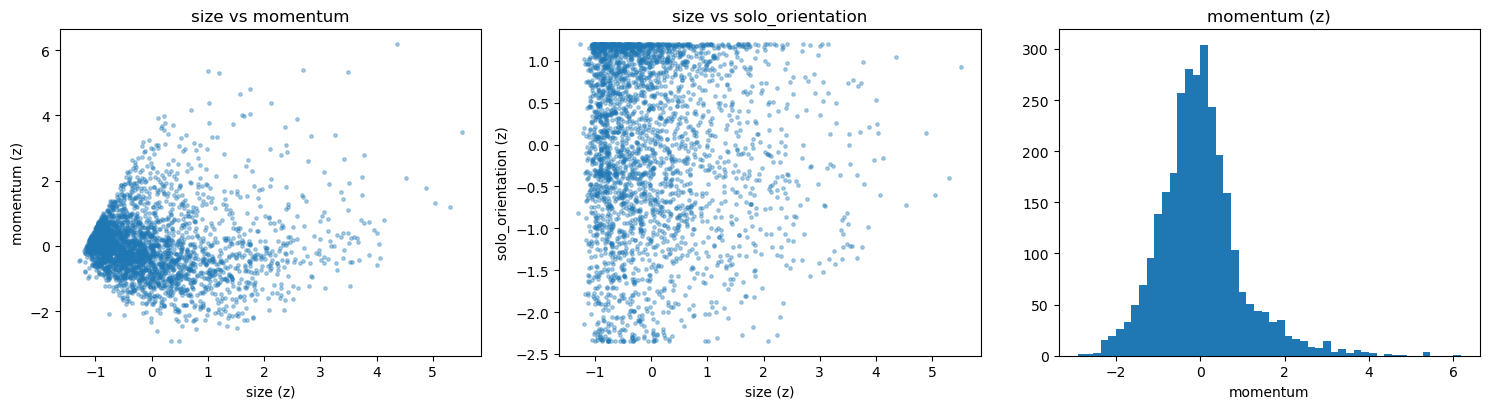

In [6]:
raw_vals = {"Streams": df["Streams"], "Daily": df["Daily"],
            "feature_share": feat["feature_share"], "solo_share": feat["solo_share"]}
interp = pd.DataFrame({s: {n: spearmanr(scores_z[s], v)[0] for n, v in raw_vals.items()} for s in scores_z.columns})
print("Spearman correlation of each score with the raw inputs:"); display(interp.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(scores_z["size"], scores_z["momentum"], s=6, alpha=0.35)
ax[0].set(title="size vs momentum", xlabel="size (z)", ylabel="momentum (z)")
ax[1].scatter(scores_z["size"], scores_z["solo_orientation"], s=6, alpha=0.35)
ax[1].set(title="size vs solo_orientation", xlabel="size (z)", ylabel="solo_orientation (z)")
ax[2].hist(scores_z["momentum"], bins=50); ax[2].set(title="momentum (z)", xlabel="momentum")
plt.tight_layout(); plt.show()

In [7]:
# Artists at the extremes of each dimension: a sanity check for a music-literate reader
view = df[["Artist", "Streams", "Daily"]].join(scores_z.round(2))
for s in scores_z.columns:
    print(f"\nHighest {s}:");  display(view.nlargest(8, s))
    print(f"Lowest {s}:");     display(view.nsmallest(8, s))


Highest size:


,Artist,Streams,Daily,size,momentum,solo_orientation
2,Taylor Swift,57859.0,85.793,5.52,3.48,0.92
0,Drake,85041.3,50.775,5.30,1.20,-0.40
1,Bad Bunny,67533.0,44.820,5.04,1.32,-0.60
3,The Weeknd,53665.2,44.437,4.89,1.77,0.14
11,Travis Scott,37489.0,38.359,4.53,2.09,-0.72
101,Olivia Rodrigo,12161.1,71.896,4.36,6.18,1.04
10,Kanye West,37667.2,24.157,4.13,0.79,-0.16
5,Justin Bieber,47525.7,18.868,4.06,-0.37,-0.61


Lowest size:


,Artist,Streams,Daily,size,momentum,solo_orientation
2940,Larry,741.5,0.002,-1.29,-0.46,-0.81
2914,Bobby Helms,750.7,0.023,-1.27,-0.42,1.20
2953,O.T. Genasis,736.4,0.107,-1.21,-0.15,0.14
2494,In This Moment,868.0,0.006,-1.19,-0.77,1.02
2667,Styles Of Beyond,814.9,0.055,-1.19,-0.50,-2.15
2875,Marian Hill,760.5,0.106,-1.19,-0.22,0.20
2463,Lars WinnerbÃ¤ck,876.5,0.004,-1.18,-0.79,0.96
2859,Justin Jesso,764.2,0.111,-1.18,-0.22,-1.78



Highest momentum:


,Artist,Streams,Daily,size,momentum,solo_orientation
101,Olivia Rodrigo,12161.1,71.896,4.36,6.18,1.04
485,Zach Bryan,4001.4,24.173,2.69,5.39,1.11
1989,V,1081.9,8.784,1.00,5.35,0.96
225,Peso Pluma,7553.2,37.826,3.49,5.34,-1.19
1722,Young Miko,1268.3,9.798,1.19,5.31,-1.40
945,Jung Kook,2206.5,12.408,1.74,4.80,-0.81
1049,Latto,1991.4,10.856,1.57,4.65,-1.08
607,Grupo Frontera,3268.7,14.428,2.12,4.39,-0.76


... (2 outputs left out)


Highest solo_orientation:


,Artist,Streams,Daily,size,momentum,solo_orientation
50,Harry Styles,18906.5,12.693,3.14,0.45,1.2
64,The Beatles,16673.3,8.152,2.69,-0.46,1.2
70,Arctic Monkeys,15544.5,12.980,3.03,0.91,1.2
87,Red Hot Chili Peppers,13261.8,6.860,2.41,-0.42,1.2
128,Die drei ???,10732.1,6.122,2.19,-0.28,1.2
139,AC/DC,10124.2,5.824,2.11,-0.28,1.2
155,Luis Miguel,9536.1,8.025,2.32,0.65,1.2
165,Nirvana,9195.0,5.892,2.06,-0.05,1.2


Lowest solo_orientation:


,Artist,Streams,Daily,size,momentum,solo_orientation
150,Disney,9786.7,5.795,2.08,-0.22,-2.34
387,Ryan Lewis,4923.0,2.200,0.97,-0.99,-2.34
429,Mambo Kingz,4474.5,2.630,1.02,-0.43,-2.34
903,Silk Sonic,2311.8,1.675,0.32,0.05,-2.34
1107,The Greatest Showman Ensemble,1901.3,0.536,-0.31,-1.15,-2.34
1200,Die Kita-FrÃ¶sche,1774.9,1.373,0.04,0.24,-2.34
1237,LSD,1718.1,0.622,-0.32,-0.79,-2.34
1397,Okieriete Onaodowan,1548.0,0.469,-0.48,-0.86,-2.34


## 6. Stability (bootstrap)

Artists are resampled with replacement and each block's PCA is refit. Because each block has two variables, the loadings are fixed by mathematics, so stability is reported for what the data *do* determine: the share of each block's variance carried by the component. A wide interval would mean the dimension is not well defined.

In [8]:
rng = np.random.default_rng(RNG_SEED)
rows = {f"{b} PC{k+1}": [] for b, k in {(s[0], s[1]) for s in SCORES}}
for _ in range(N_BOOT):
    idx = rng.integers(0, len(feat), len(feat))
    fb = feat.iloc[idx]; Zb = (fb - fb.mean()) / fb.std(ddof=0)
    for b, k in {(s[0], s[1]) for s in SCORES}:
        rows[f"{b} PC{k+1}"].append(PCA().fit(Zb[BLOCKS[b]]).explained_variance_ratio_[k])
stab = pd.DataFrame({name: {"estimate": share_blocks[name.split()[0]][int(name[-1]) - 1],
                            "CI 2.5%": np.percentile(v, 2.5), "CI 97.5%": np.percentile(v, 97.5)}
                     for name, v in rows.items()}).T
print("Share of block variance carried by each component (bootstrap 95% interval):"); display(stab.round(3))

Share of block variance carried by each component (bootstrap 95% interval):


,estimate,CI 2.5%,CI 97.5%
composition PC1,0.874,0.866,0.884
streams PC1,0.911,0.904,0.920
streams PC2,0.089,0.080,0.096


## 7. Export for the quantile-regression notebooks

The output keeps `Artist` and `Streams` so it joins to the song file the same way as before (artist name + lifetime streams; names alone are not unique, e.g. two artists called "Eve"). In the song models, replace the single `APS` regressor with `size`, `momentum` and `solo_orientation`. They are already unit-variance and mutually uncorrelated across blocks, so VIFs between them stay near 1.

In [9]:
out = df[["Artist", "Streams", "Daily"]].join(scores_z).sort_values("size", ascending=False).reset_index(drop=True)
out.to_csv(OUT_FILE, index=False)
loadings.to_csv("artist_pca_loadings.csv", index=False)
print("Saved", OUT_FILE, "and artist_pca_loadings.csv ->", out.shape)
display(out.head(10).round(3))

Saved artist_pca_scores.csv and artist_pca_loadings.csv -> (2994, 6)


,Artist,Streams,Daily,size,momentum,solo_orientation
0,Taylor Swift,57859.0,85.793,5.517,3.485,0.922
1,Drake,85041.3,50.775,5.298,1.204,-0.403
2,Bad Bunny,67533.0,44.820,5.041,1.324,-0.602
3,The Weeknd,53665.2,44.437,4.886,1.771,0.144
4,Travis Scott,37489.0,38.359,4.527,2.093,-0.723
5,Olivia Rodrigo,12161.1,71.896,4.361,6.181,1.041
6,Kanye West,37667.2,24.157,4.126,0.791,-0.159
7,Justin Bieber,47525.7,18.868,4.063,-0.367,-0.607
8,Eminem,42029.0,20.175,4.041,0.069,0.138
9,Post Malone,38002.7,21.095,4.015,0.398,0.243
